# 7. Explainable AI

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

trained_models = joblib.load("../data/05_trained_models.pkl")
processed_data = joblib.load("../data/03_processed_data.pkl")

random_forest_model = trained_models["random_forest_model"]
X_train = processed_data["X_train"]
X_test = processed_data["X_test"]

print("Random Forest model and test data loaded successfully!")


Random Forest model and test data loaded successfully!


In [2]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Random Forest model:", type(random_forest_model).__name__)
print("Features expected by model:", random_forest_model.n_features_in_)

Training data shape: (19760, 21)
Testing data shape: (4940, 21)
Random Forest model: RandomForestClassifier
Features expected by model: 21


## Explainable AI - Random Forest Feature Importance

Random Forest provides feature importance scores that show the relative
contribution of each feature to the model's predictions.

This helps us understand which factors are most influential in predicting
loan recovery and can support debt recovery strategies.

In [3]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
8,previous_defaults,0.303841
12,contact_success_rate,0.202077
2,credit_score,0.179941
9,payment_delays,0.107626
1,income,0.050238
10,employment_years,0.032161
0,age,0.022678
6,debt_to_income,0.021192
5,interest_rate,0.020991
3,loan_amount,0.015460


## Top Features Influencing Loan Recovery

The feature importance visualization highlights the variables that have
the greatest influence on the Random Forest model's predictions.

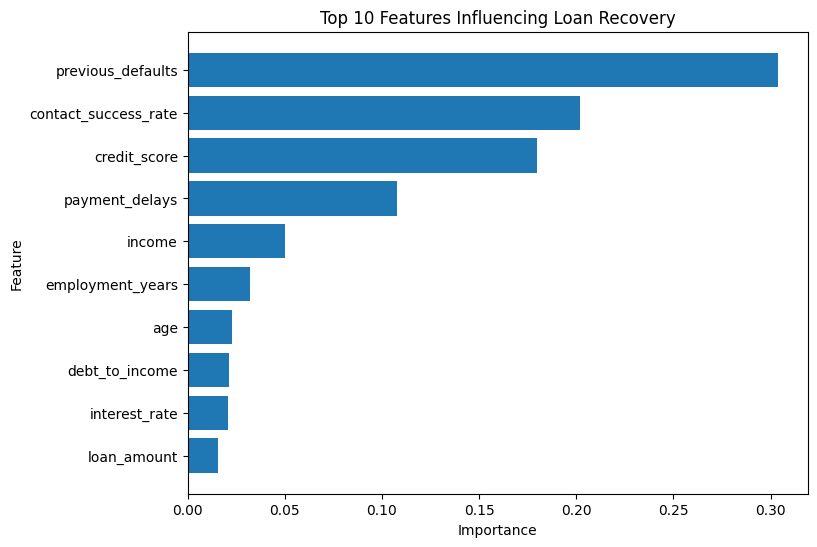

In [4]:
plt.figure(figsize=(8, 6))

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Loan Recovery")

plt.show()

## SHAP Analysis

In [5]:

import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")


SHAP version: 0.52.0
SHAP imported successfully!


C:\Users\manth\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
explainer = shap.TreeExplainer(random_forest_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


SHAP values calculated successfully!
X_test shape: (4940, 21)
Class 1 SHAP shape: (4940, 21)


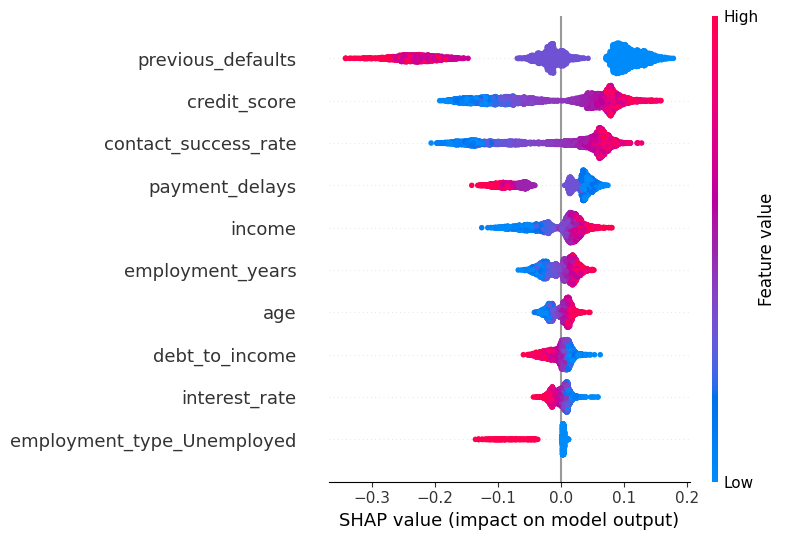

In [7]:
shap_values = explainer.shap_values(X_test)

# SHAP versions differ: classification outputs may be a list or a 3D array.
# Select the SHAP values for class 1 (loan recovered).
if isinstance(shap_values, list):
    if len(shap_values) < 2:
        values_to_plot = np.asarray(shap_values[0])
    else:
        values_to_plot = np.asarray(shap_values[1])
else:
    values_to_plot = np.asarray(shap_values)
    if values_to_plot.ndim == 3:
        # Common format: (samples, features, classes)
        if values_to_plot.shape[0] == X_test.shape[0] and values_to_plot.shape[1] == X_test.shape[1]:
            values_to_plot = values_to_plot[:, :, 1]
        # Alternate format: (classes, samples, features)
        elif values_to_plot.shape[1] == X_test.shape[0] and values_to_plot.shape[2] == X_test.shape[1]:
            values_to_plot = values_to_plot[1, :, :]
        else:
            raise ValueError(
                f"Unrecognized 3D SHAP shape {values_to_plot.shape}; "
                f"X_test shape is {X_test.shape}."
            )

# Check that the selected SHAP values line up with the test features.
if values_to_plot.ndim != 2 or values_to_plot.shape != X_test.shape:
    raise ValueError(
        f"SHAP shape {values_to_plot.shape} does not match X_test shape {X_test.shape}. "
        "Check that the SHAP values and test data come from the same processed dataset."
    )

print("SHAP values calculated successfully!")
print("X_test shape:", X_test.shape)
print("Class 1 SHAP shape:", values_to_plot.shape)

shap.summary_plot(
    values_to_plot,
    X_test,
    max_display=10,
    show=True
)


### SHAP Insights

The SHAP analysis provides both feature importance and the direction of
feature influence on loan recovery predictions.

The results show that previous defaults and payment delays generally push
predictions toward non-recovery, while higher credit scores and higher
contact success rates generally push predictions toward recovery.

These insights can be used to design targeted debt recovery strategies.